# Лабораторная работа №9: Fine-tuning VLM с помощью LLaMA-Factory

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Преобразовать мультимодальные данные в instruction format.
- Сформировать QLoRA YAML и запустить SFT.
- Сравнить base и adapter, включая OOD slice.


## Теоретическая часть

SFT минимизирует autoregressive loss только на целевом ответе. QLoRA хранит base weights в 4-bit NF4 и обучает low-rank update $\Delta W=BA$, что уменьшает память. LLaMA-Factory фиксирует pipeline в YAML-конфигурации.


### Математическая постановка

$$W'=W_q+\frac{\alpha}{r}BA,\quad B\in\mathbb R^{d\times r},\ A\in\mathbb R^{r\times k}.$$ Обучаются только $A,B$; сравнение проводится с той же base model и evaluation set.


### Материалы

- [LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)
- [QLoRA](https://arxiv.org/abs/2305.14314)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Вход — лицензированный предметный корпус `data/lab9/manifest.jsonl` с независимыми train/validation/ID/OOD. Получение и экспертная проверка данных обязательны; файл не заменяется выдуманным изображением. В Colab установите совместимый LLaMA-Factory из зафиксированного commit и запишите commit в отчёт. CLI запускается непосредственно из ноутбука. Полный режим означает фактическое обучение и сравнение; `FAST_DEV_RUN` обучает два шага только для проверки стека. Оценку общей способности выполните на отдельном общем VQA-наборе с заранее выбранной метрикой.

In [1]:
# ===== 0. Установка LLaMA-Factory (зафиксированный релиз) + фикс SSL =====
import os, sys, json, subprocess
from pathlib import Path
import importlib.metadata as im

try:
    import truststore; truststore.inject_into_ssl(); print("truststore ✔")
except Exception:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "truststore"], check=True)
    import truststore; truststore.inject_into_ssl(); print("truststore ✔ (доустановлен)")

def _v(d):
    try: return im.version(d)
    except Exception: return None

LF_TAG = os.getenv("LF_TAG", "v0.9.3")  # релиз с поддержкой Qwen2.5-VL; коммит запишем в version.json
if _v("llamafactory") is None:
    print(f"Ставлю llamafactory из git@{LF_TAG} (несколько минут, потянет peft/trl/datasets)...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    f"git+https://github.com/hiyouga/LLaMA-Factory.git@{LF_TAG}"], check=True)
else:
    print("llamafactory уже установлен:", _v("llamafactory"))

commit = None
try:
    du = json.loads(im.distribution("llamafactory").read_text("direct_url.json") or "{}")
    commit = (du.get("vcs_info") or {}).get("commit_id")
except Exception as e:
    print("commit из direct_url.json не прочитался:", e)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/lf_commit.json").write_text(json.dumps({"tag": LF_TAG, "commit": commit}, indent=2))
print("commit:", commit)
for d in ("torch", "transformers", "accelerate", "peft", "trl", "bitsandbytes", "datasets"):
    print(f"{d:14s} {_v(d)}")
print("Если pip менял версии torch/transformers — Restart ядра и продолжайте со следующей ячейки.")

truststore ✔
llamafactory уже установлен: 0.9.3
commit: ca75f1edf3cb50343ed1c98605141c3e22075b5f
torch          2.6.0+cu124
transformers   4.52.4
accelerate     1.7.0
peft           0.15.2
trl            0.9.6
bitsandbytes   0.50.2
datasets       3.6.0
Если pip менял версии torch/transformers — Restart ядра и продолжайте со следующей ячейки.


In [2]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


In [3]:
# === Encoding shim (Windows): все текстовые файлы по умолчанию UTF-8 ===
import pathlib

def _install_utf8_shim():
    if getattr(pathlib.Path.write_text, "_utf8_shim", False):
        return
    _wt, _rt = pathlib.Path.write_text, pathlib.Path.read_text
    def write_text(self, data, *args, **kwargs):
        kwargs.setdefault("encoding", "utf-8")
        return _wt(self, data, *args, **kwargs)
    def read_text(self, *args, **kwargs):
        kwargs.setdefault("encoding", "utf-8")
        return _rt(self, *args, **kwargs)
    write_text._utf8_shim = read_text._utf8_shim = True
    pathlib.Path.write_text, pathlib.Path.read_text = write_text, read_text

_install_utf8_shim()
print("шим стоит: read_text/write_text теперь utf-8 по умолчанию")

# Перекодируем уже записанные файлы cp1251 -> UTF-8, чтобы НЕ перекачивать датасет
d = pathlib.Path("data/lab9")
if d.is_dir():
    for p in list(d.glob("manifest*.jsonl")) + list(d.glob("ATTRIBUTION.md")):
        raw = p.read_bytes()
        try:
            raw.decode("utf-8"); print("уже utf-8:", p.name)
        except UnicodeDecodeError:
            text = None
            for enc in ("cp1251", "cp1252", "latin-1"):
                try:
                    text = raw.decode(enc); break
                except UnicodeDecodeError:
                    continue
            p.write_text(text, encoding="utf-8")
            print("перекодировал в utf-8:", p.name)
else:
    print("папки data/lab9 нет — перекодировать нечего")

шим стоит: read_text/write_text теперь utf-8 по умолчанию
уже utf-8: manifest.jsonl
уже utf-8: ATTRIBUTION.md


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Манифест и независимые разбиения

*Вес: 1 балл.*

**Постановка.** Загрузите ScienceQA функцией prepare_scienceqa. Сформируйте 512 train и по 64 validation, ID, OOD и general примера с изображениями. ID: natural science, классы 1–6; OOD: тот же предмет, классы 7–12; general: другие предметы. Используйте официальные split и исключите повторные изображения по хешу.

**Результат.** manifest.jsonl и ATTRIBUTION.md.

**Критерий принятия.** Количество записей соответствует протоколу; ни одно изображение не используется в двух разбиениях; версия и лицензия источника указаны.


In [4]:
# === Диагностика + ремонт манифеста ===
import json, pathlib
from collections import Counter

d = pathlib.Path("data/lab9")
EXPECT = {
    "manifest.jsonl": {"train": 512, "validation": 64, "id_test": 64, "ood_test": 64, "general_test": 64},
    "manifest-smoke.jsonl": {"train": 8, "validation": 4, "id_test": 4, "ood_test": 4, "general_test": 4},
}

files = sorted(d.glob("manifest*.jsonl")) if d.is_dir() else []
if not files:
    print("манифестов нет вообще — просто запусти setup-ячейку, prepare соберёт их с нуля")

for p in files:
    raw = p.read_bytes()
    print("=" * 60)
    print(p.name, "| размер:", len(raw), "байт")
    print("начало файла:", raw[:120])
    text = raw.decode("utf-8-sig", errors="replace")   # utf-8-sig срезает BOM, если он есть
    lines = text.splitlines()
    good, bad = [], []
    for i, s in enumerate(lines):
        if not s.strip():
            continue  # пустые строки выбрасываем
        try:
            r = json.loads(s)
            assert isinstance(r, dict) and "id" in r and "split" in r
            good.append(s)
        except Exception:
            bad.append((i + 1, s[:80]))
    cnt = Counter(json.loads(s)["split"] for s in good)
    print("строк всего:", len(lines), "| валидных:", len(good), "| мусорных:", len(bad))
    print("по сплитам:", dict(cnt))
    if bad:
        print("пример мусора:", bad[:2])
    exp = EXPECT[p.name]
    if dict(cnt) == exp and not bad:
        p.write_text("\n".join(good) + "\n", encoding="utf-8")
        print("-> ОТРЕМОНТИРОВАН: пустые строки убраны, состав совпадает с протоколом")
    else:
        bak = p.with_suffix(".jsonl.broken")
        p.rename(bak)
        print(f"-> состав не соответствует протоколу: файл убран в {bak.name}")
        print("   при следующем запуске setup prepare соберёт этот манифест заново")

manifest.jsonl | размер: 626292 байт
начало файла: b'{"id": "scienceqa-train-9", "split": "train", "image": "C:\\\\Users\\\\eric1\\\\Desktop\\\\SOTA\\\\lab9\\\\data\\\\lab9\\\\7059b2a9d6213'
строк всего: 768 | валидных: 768 | мусорных: 0
по сплитам: {'train': 512, 'validation': 64, 'ood_test': 64, 'general_test': 64, 'id_test': 64}
-> ОТРЕМОНТИРОВАН: пустые строки убраны, состав совпадает с протоколом


In [5]:
# ===== Этап 1. Манифест и независимые разбиения =====
from collections import Counter, defaultdict

DATA_DIR = Path("data/lab9")
FAST = globals().get("FAST_DEV_RUN", (DATA_DIR / "manifest-smoke.jsonl").exists())

manifest_path = prepare_scienceqa(DATA_DIR, smoke=FAST)
records = [json.loads(s) for s in manifest_path.read_text(encoding="utf-8").splitlines() if s.strip()]

LIMITS = {"train": 8 if FAST else 512, "validation": 4 if FAST else 64,
          "id_test": 4 if FAST else 64, "ood_test": 4 if FAST else 64, "general_test": 4 if FAST else 64}
counts = {s: sum(r["split"] == s for r in records) for s in LIMITS}
assert counts == LIMITS, f"Количество записей не совпало: {counts} != {LIMITS}"

missing = [r["id"] for r in records if not Path(r["image"]).is_file()]
assert not missing, f"Отсутствуют файлы изображений: {missing[:5]}"

# ни одно изображение не используется в двух разбиениях (и вообще не повторяется)
hash_splits = defaultdict(set)
for r in records: hash_splits[r["image_sha256"]].add(r["split"])
cross_split = {h: ss for h, ss in hash_splits.items() if len(ss) > 1}
dup_any = {h: c for h, c in Counter(r["image_sha256"] for r in records).items() if c > 1}
assert not dup_any, f"Повторные изображения: {len(dup_any)}"
assert not cross_split, f"Изображение в двух split: {len(cross_split)}"

attr_path = DATA_DIR / "ATTRIBUTION.md"
assert attr_path.is_file() and "CC-BY-SA-4.0" in attr_path.read_text(encoding="utf-8"), "Нет атрибуции"

save_json("manifest_check.json", {"manifest": str(manifest_path), "fast": FAST, "counts": counts,
    "unique_images": len(hash_splits), "duplicate_images": len(dup_any),
    "images_in_two_splits": len(cross_split),
    "license": "CC-BY-SA-4.0 (dataset card); MIT (код lupantech/ScienceQA)",
    "source": "https://huggingface.co/datasets/derek-thomas/ScienceQA @ f18b0a70359ebfb41f658fd564208d0355b013f4"})
print(f"Манифест: {len(records)} записей, сплиты: {counts}")
print(f"Уникальных изображений: {len(hash_splits)} | повторов: {len(dup_any)} | пересечений split: {len(cross_split)}")
print("-> artifacts/manifest_check.json (объёмы, дедуп по хешу, лицензия и ревизия источника)")

Манифест: 768 записей, сплиты: {'train': 512, 'validation': 64, 'id_test': 64, 'ood_test': 64, 'general_test': 64}
Уникальных изображений: 768 | повторов: 0 | пересечений split: 0
-> artifacts/manifest_check.json (объёмы, дедуп по хешу, лицензия и ревизия источника)


### Визуальный аудит корпуса

*Вес: 1 балл.*

**Постановка.** Декодируйте изображения и постройте сетку примеров с вопросами и правильными буквами. Подсчитайте распределение ответов по каждому split: возможный перевес одной буквы следует учитывать при интерпретации accuracy.

**Результат.** data_profile.json и data_preview.png.

**Критерий принятия.** Показаны реальные изображения; правильная буква соответствует индексированному варианту; представлены частоты всех букв отдельно по split.


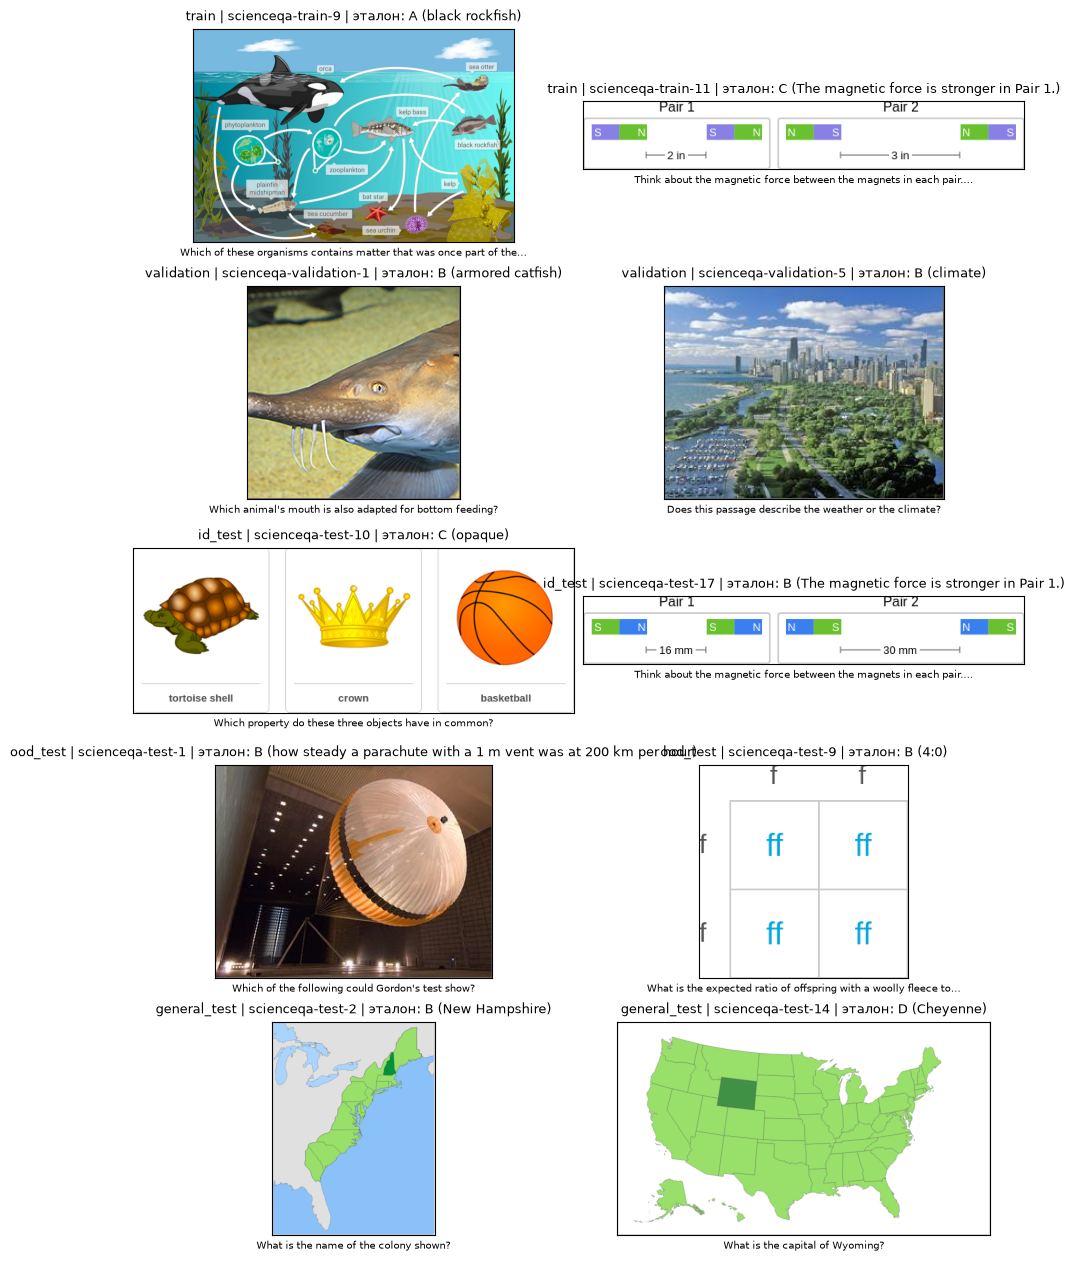

Частоты букв по split -> artifacts/data_profile.json
train         n=512 | A:209 B:230 C:72 D:1 E:0
validation    n= 64 | A:24 B:32 C:8 D:0 E:0
id_test       n= 64 | A:26 B:27 C:11 D:0 E:0
ood_test      n= 64 | A:25 B:27 C:9 D:3 E:0
general_test  n= 64 | A:13 B:21 C:17 D:13 E:0
Сетка примеров -> artifacts/data_preview.png


In [6]:
# ===== Этап 2. Визуальный аудит: data_profile.json + data_preview.png =====
import textwrap
import matplotlib.pyplot as plt
from PIL import Image as PILImage

LETTERS = ["A", "B", "C", "D", "E"]
SPLITS = ["train", "validation", "id_test", "ood_test", "general_test"]

profile = {}
for s in SPLITS:
    rows = [r for r in records if r["split"] == s]
    dist = Counter(r["answer"] for r in rows)
    profile[s] = {"n": len(rows), "letter_freq": {L: int(dist.get(L, 0)) for L in LETTERS},
                  "grades": sorted({r["grade"] for r in rows})}
save_json("data_profile.json", {
    "note": "частоты всех букв отдельно по split; перевес одной буквы учитываем при интерпретации accuracy",
    "splits": profile})

# сетка примеров: по 2 изображения из каждого split
fig, axes = plt.subplots(len(SPLITS), 2, figsize=(9, 2.5 * len(SPLITS)), constrained_layout=True)
for i, s in enumerate(SPLITS):
    rows = [r for r in records if r["split"] == s]
    for j, ax in enumerate(axes[i]):
        if j < len(rows):
            r = rows[j]
            ax.imshow(PILImage.open(r["image"]).convert("RGB"))
            q = textwrap.shorten(r["question"].split("\nA. ")[0], width=70, placeholder="…")
            ax.set_title(f"{s} | {r['id']} | эталон: {r['answer']} ({r['choices'][r['answer_index']]})",
                         fontsize=9)
            ax.set_xlabel(q, fontsize=7)
        ax.set_xticks([]); ax.set_yticks([])
plt.savefig("artifacts/data_preview.png", dpi=130)
plt.show()

print("Частоты букв по split -> artifacts/data_profile.json")
for s in SPLITS:
    f = profile[s]["letter_freq"]
    print(f"{s:13s} n={profile[s]['n']:3d} | " + " ".join(f"{L}:{f[L]}" for L in LETTERS))
print("Сетка примеров -> artifacts/data_preview.png")

### Экспорт мультимодального датасета

*Вес: 1 балл.*

**Постановка.** Преобразуйте записи в ShareGPT: сообщение пользователя содержит один маркер <image> и вопрос с вариантами, ответ ассистента — правильную букву. Зарегистрируйте train и validation в dataset_info.json.

**Результат.** train.json, validation.json и dataset_info.json.

**Критерий принятия.** Пути изображений разрешаются; роли и столбцы соответствуют формату LLaMA-Factory; test не попал в обучение.


In [7]:
# ===== Этап 3. ShareGPT: train.json, validation.json, dataset_info.json =====
def to_sharegpt(rows):
    out = []
    for r in rows:
        assert Path(r["image"]).is_file(), f"нет изображения: {r['image']}"
        out.append({"id": r["id"],
                    "messages": [{"role": "user", "content": "<image>\n" + r["question"]},
                                 {"role": "assistant", "content": r["answer"]}],
                    "images": [r["image"]]})
    return out

train_rows = to_sharegpt([r for r in records if r["split"] == "train"])
val_rows   = to_sharegpt([r for r in records if r["split"] == "validation"])

train_ids = {x["id"] for x in train_rows} | {x["id"] for x in val_rows}
test_ids = {r["id"] for r in records if r["split"] in ("id_test", "ood_test", "general_test")}
assert not (train_ids & test_ids), "test попал в обучение!"

(ARTIFACTS / "train.json").write_text(json.dumps(train_rows, ensure_ascii=False, indent=1), encoding="utf-8")
(ARTIFACTS / "validation.json").write_text(json.dumps(val_rows, ensure_ascii=False, indent=1), encoding="utf-8")

_tags = {"role_tag": "role", "content_tag": "content",
         "user_tag": "user", "assistant_tag": "assistant", "image_tag": "<image>"}
_cols = {"messages": "messages", "images": "images"}
dataset_info = {
    "lab9_train": {"file_name": "train.json", "formatting": "sharegpt", "columns": _cols, "tags": _tags},
    "lab9_val":   {"file_name": "validation.json", "formatting": "sharegpt", "columns": _cols, "tags": _tags},
}
(ARTIFACTS / "dataset_info.json").write_text(json.dumps(dataset_info, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"train={len(train_rows)}, validation={len(val_rows)} -> {ARTIFACTS}/train.json, validation.json")
print(f"dataset_info.json -> {ARTIFACTS} (папка будет data_dir для llamafactory)")
_ex = train_rows[0]
print("Пример:", json.dumps({"id": _ex["id"], "messages": [
    {"role": "user", "content": _ex["messages"][0]["content"][:70] + "…"},
    {"role": "assistant", "content": _ex["messages"][1]["content"]}],
    "images": ["<путь к png>"]}, ensure_ascii=False))

train=512, validation=64 -> artifacts/train.json, validation.json
dataset_info.json -> artifacts (папка будет data_dir для llamafactory)
Пример: {"id": "scienceqa-train-9", "messages": [{"role": "user", "content": "<image>\nWhich of these organisms contains matter that was once part of…"}, {"role": "assistant", "content": "A"}], "images": ["<путь к png>"]}


### Конфигурация QLoRA SFT

*Вес: 1 балл.*

**Постановка.** Настройте Qwen2.5-VL-3B-Instruct, NF4, LoRA rank 8 и alpha 16, batch 1 с accumulation 16, learning rate 1e-4 и 100 шагов. Включите validation каждые 20 шагов.

**Результат.** sft.yaml.

**Критерий принятия.** YAML содержит реальные идентификаторы данных и модели, включает do_train/do_eval и сохраняет checkpoint; полный режим не ограничен двумя smoke-шагами.


In [8]:
# ===== Этап 4. Конфиг QLoRA SFT -> artifacts/sft.yaml (+ fingerprint для этапа 5) =====
import hashlib

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
OUT_DIR = (ARTIFACTS / ("lab9_adapter_fast" if FAST else "lab9_adapter")).resolve()
YAML_PATH = (ARTIFACTS / "sft.yaml").resolve()

sft_yaml = f"""### LLaMA-Factory QLoRA SFT (lab9) — {'FAST smoke: 2 шага' if FAST else 'полный прогон: 100 шагов'}
model_name_or_path: {MODEL_ID}
trust_remote_code: true

stage: sft
do_train: true
do_eval: true
finetuning_type: lora
lora_rank: 8
lora_alpha: 16
lora_dropout: 0.05
lora_target: all

quantization_bit: 4
quantization_method: bitsandbytes
quantization_type: nf4
double_quantization: true

template: qwen2_vl
freeze_vision_tower: true
freeze_multi_modal_projector: true

data_dir: {ARTIFACTS.resolve()}
dataset: lab9_train
eval_dataset: lab9_val
cutoff_len: 2048
max_samples: {8 if FAST else 100000}

per_device_train_batch_size: 1
per_device_eval_batch_size: 1
gradient_accumulation_steps: {1 if FAST else 16}
learning_rate: 1.0e-04
num_train_epochs: 3.0
max_steps: {2 if FAST else 100}
lr_scheduler_type: cosine
warmup_ratio: 0.03
logging_steps: {1 if FAST else 5}
save_steps: {2 if FAST else 20}
eval_strategy: steps
eval_steps: {2 if FAST else 20}
save_total_limit: 3
fp16: true
gradient_checkpointing: true
report_to: none

output_dir: {OUT_DIR}
resume_from_checkpoint: null
"""

def fingerprint(text):
    body = "\n".join(l for l in text.splitlines() if not l.strip().startswith("resume_from_checkpoint"))
    return hashlib.sha256(body.encode()).hexdigest()

YAML_PATH.write_text(sft_yaml, encoding="utf-8")
(ARTIFACTS / "sft_fingerprint.txt").write_text(fingerprint(sft_yaml), encoding="utf-8")
save_json("run_paths.json", {"fast": FAST, "model_id": MODEL_ID, "yaml": str(YAML_PATH),
                             "output_dir": str(OUT_DIR), "data_dir": str(ARTIFACTS.resolve()),
                             "fingerprint": fingerprint(sft_yaml)})
print("sft.yaml ->", YAML_PATH)
print(f"output_dir: {OUT_DIR} | fast={FAST} | fingerprint={fingerprint(sft_yaml)[:12]}…")

sft.yaml -> C:\Users\eric1\Desktop\SOTA\lab9\artifacts\sft.yaml
output_dir: C:\Users\eric1\Desktop\SOTA\lab9\artifacts\lab9_adapter | fast=False | fingerprint=eaa8950b5719…


### Возобновление обучения

*Вес: 1 балл.*

**Постановка.** Реализуйте выбор последнего checkpoint по числовому global step. Отсутствие checkpoint означает новый запуск; существующий должен принадлежать той же конфигурации. Объясните отличие загрузки весов от восстановления состояния оптимизатора.

**Результат.** resume_protocol.json и обновлённый sft.yaml.

**Критерий принятия.** Выбор не основан на лексикографическом порядке; зафиксированы выбранный путь либо null и режим нового/возобновляемого запуска.


In [9]:
# ===== Этап 5. Resume: последний checkpoint по ЧИСЛОВОМУ global step =====
run_paths = json.loads((ARTIFACTS / "run_paths.json").read_text(encoding="utf-8"))
OUT_DIR, YAML_PATH = Path(run_paths["output_dir"]), Path(run_paths["yaml"])

def find_checkpoints(out_dir):
    found = []
    for p in Path(out_dir).glob("checkpoint-*"):
        m = re.fullmatch(r"checkpoint-(\d+)", p.name)
        if m and p.is_dir() and (p / "adapter_model.safetensors").is_file() and (p / "trainer_state.json").is_file():
            found.append((int(m.group(1)), p))
    return sorted(found)   # сортировка по ЧИСЛУ шага, не по имени строки

ckpts = find_checkpoints(OUT_DIR)
fp_match = (ARTIFACTS / "sft_fingerprint.txt").read_text() == run_paths.get("fingerprint")

if not ckpts:
    mode, selected = "fresh", None
    print("Валидных checkpoint'ов нет -> новый запуск (resume_from_checkpoint: null)")
else:
    mode = "resume"
    step, path = ckpts[-1]
    selected = str(path)
    lex_worst = sorted(p.name for _, p in ckpts)[-1]  # что выбрал бы лексикографический порядок
    print(f"Checkpoints: {[s for s, _ in ckpts]} -> выбран checkpoint-{step} (по числу)")
    if lex_worst != path.name:
        print(f"  ловушка: лексикографическая сортировка имён дала бы '{lex_worst}'")
    if not fp_match:
        raise RuntimeError("Конфиг (fingerprint) изменился с прошлого прогона — checkpoint чужой. "
                           "Удалите output_dir или верните прежний sft.yaml.")

lines = [l for l in YAML_PATH.read_text(encoding="utf-8").splitlines()
         if not l.strip().startswith("resume_from_checkpoint")]
lines.append(f"resume_from_checkpoint: {selected if selected else 'null'}")
YAML_PATH.write_text("\n".join(lines) + "\n", encoding="utf-8")

save_json("resume_protocol.json", {
    "mode": mode, "checkpoints_found": [s for s, _ in ckpts], "selected": selected,
    "selection_rule": "max(int(global_step)) из имён checkpoint-N с проверкой содержимого; НЕ лексикографический порядок",
    "config_fingerprint_match": bool(fp_match),
    "weights_vs_optimizer": (
        "Загрузка весов (adapter_model.safetensors) возвращает только параметры модели: инференс возможен, "
        "но обучение начнётся с шага 0 — без optimizer.pt (моменты Adam m и v), расписания lr и RNG; "
        "cosine-расписание запустится заново с максимума. resume_from_checkpoint через trainer_state.json "
        "восстанавливает и веса, и состояние оптимизатора/шедулера/RNG — шаги продолжаются с global_step."),
})
print("-> artifacts/resume_protocol.json | sft.yaml: resume_from_checkpoint =", selected or "null")

Валидных checkpoint'ов нет -> новый запуск (resume_from_checkpoint: null)
-> artifacts/resume_protocol.json | sft.yaml: resume_from_checkpoint = null


### Обучение в LLaMA-Factory

*Вес: 1 балл.*

**Постановка.** Выполните llamafactory-cli train с сохранением полного лога. Проверьте фактически выполненное число шагов и наличие обученного адаптера.

**Результат.** lab9_adapter, train.log и version.json.

**Критерий принятия.** Процесс завершился без ошибки; сохранены adapter_model.safetensors и trainer_state.json; запуск с FAST_DEV_RUN=True не принимается за полный эксперимент.


In [10]:
# === Фикс сети: указываем обучению ЛОКАЛЬНУЮ копию модели (без ходок в интернет) ===
from pathlib import Path
import yaml
from huggingface_hub import snapshot_download

REPO = "Qwen/Qwen2.5-VL-3B-Instruct"

local_dir = None
try:
    local_dir = snapshot_download(REPO, local_files_only=True)
    print("локальная копия модели:", local_dir)
except Exception as e:
    print("НЕ НАШЁЛ модель в кэше:", e)
    print("пришли этот вывод — найдём путь к модели вручную")

if local_dir:
    patched = False
    for p in list(Path("artifacts").glob("*.yaml")) + list(Path("artifacts").glob("*.yml")):
        cfg = yaml.safe_load(p.read_text(encoding="utf-8"))
        if not isinstance(cfg, dict):
            continue
        mop = cfg.get("model_name_or_path")
        if isinstance(mop, str) and "/" in mop and not Path(mop).exists():
            cfg["model_name_or_path"] = local_dir
            p.write_text(yaml.safe_dump(cfg, allow_unicode=True, sort_keys=False), encoding="utf-8")
            print("ИСПРАВЛЕН:", p, "| model_name_or_path ->", local_dir)
            patched = True
        else:
            print("без изменений:", p.name, "| model_name_or_path =", mop)
    if not patched:
        print("нечего патчить — проверь вывод выше")

локальная копия модели: C:\Users\eric1\.cache\huggingface\hub\models--Qwen--Qwen2.5-VL-3B-Instruct\snapshots\66285546d2b821cf421d4f5eb2576359d3770cd3
ИСПРАВЛЕН: artifacts\sft.yaml | model_name_or_path -> C:\Users\eric1\.cache\huggingface\hub\models--Qwen--Qwen2.5-VL-3B-Instruct\snapshots\66285546d2b821cf421d4f5eb2576359d3770cd3


In [11]:
# === Фикс конфига: data_dir -> dataset_dir ===
import yaml
from pathlib import Path

found = False
candidates = (list(Path("artifacts").glob("*.yaml")) + list(Path("artifacts").glob("*.yml"))
              + list(Path(".").glob("*.yaml")))
for p in candidates:
    cfg = yaml.safe_load(p.read_text(encoding="utf-8"))
    if not isinstance(cfg, dict):
        continue
    if "data_dir" in cfg:
        cfg["dataset_dir"] = cfg.pop("data_dir")
        p.write_text(yaml.safe_dump(cfg, allow_unicode=True, sort_keys=False), encoding="utf-8")
        print("ИСПРАВЛЕН:", p, "| data_dir -> dataset_dir =", cfg["dataset_dir"])
        found = True
    else:
        print("без изменений:", p.name, "| dataset_dir =", cfg.get("dataset_dir", "НЕТ"))
if not found:
    print("ключа data_dir нигде не нашлось — пришли мне вывод выше, посмотрим ключи конфига")

ИСПРАВЛЕН: artifacts\sft.yaml | data_dir -> dataset_dir = C:\Users\eric1\Desktop\SOTA\lab9\artifacts


In [12]:
# ===== Этап 6. llamafactory-cli train: полный лог -> artifacts/train.log + version.json =====
import subprocess, sys, os, importlib.metadata as im
import torch

if not (ARTIFACTS / "sft.yaml").is_file(): raise RuntimeError("Сначала этап 4 (sft.yaml)")
try: im.version("llamafactory")
except im.PackageNotFoundError: raise RuntimeError("llamafactory не установлен — выполните ячейку 0 и Restart ядра")
assert torch.cuda.is_available(), "Обучение требует GPU"

run_paths = json.loads((ARTIFACTS / "run_paths.json").read_text(encoding="utf-8"))
YAML_PATH, OUT_DIR = Path(run_paths["yaml"]), Path(run_paths["output_dir"])
LOG_PATH = ARTIFACTS / "train.log"
cmd = [sys.executable, "-m", "llamafactory.cli", "train", str(YAML_PATH)]
env = os.environ.copy(); env["TOKENIZERS_PARALLELISM"] = "false"
print("Запуск:", " ".join(cmd))
print("Полный лог ->", LOG_PATH, "| в консоль печатаются только потери/итоги\n")

rc, proc = None, None
with LOG_PATH.open("w", encoding="utf-8") as log:
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=env)
    for line in proc.stdout:
        log.write(line); log.flush()
        s = line.strip()
        if s.startswith("{'loss'") or "train_runtime" in s or "Traceback" in s or s.startswith(("RuntimeError", "ValueError")):
            print(s[:220])
    rc = proc.wait()

if rc != 0:
    tail = LOG_PATH.read_text(encoding="utf-8").splitlines()[-30:]
    raise RuntimeError(f"llamafactory упал с кодом {rc}. Хвост лога:\n" + "\n".join(tail))

ckpts = sorted(Path(OUT_DIR).glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[-1]))
state_path = OUT_DIR / "trainer_state.json"
if not state_path.is_file():
    assert ckpts, "trainer_state.json не найден — обучение не сохранило состояние"
    state_path = ckpts[-1] / "trainer_state.json"
state = json.loads(state_path.read_text(encoding="utf-8"))
steps_done, steps_expected = int(state["global_step"]), (2 if run_paths["fast"] else 100)
adapter_ok = (OUT_DIR / "adapter_model.safetensors").is_file() or (ckpts and (ckpts[-1] / "adapter_model.safetensors").is_file())
assert adapter_ok, "adapter_model.safetensors не найден"
assert steps_done == steps_expected, f"Сделано {steps_done} шагов из {steps_expected}"
print(f"\nОбучение завершено: global_step={steps_done}/{steps_expected} (fast={run_paths['fast']}), адаптер на месте")

def _v(d):
    try: return im.version(d)
    except Exception: return None
commit = lf_tag = None
try:
    du = json.loads(im.distribution("llamafactory").read_text("direct_url.json") or "{}")
    commit = (du.get("vcs_info") or {}).get("commit_id")
except Exception: pass
try: lf_tag = json.loads((ARTIFACTS / "lf_commit.json").read_text()).get("tag")
except Exception: pass
save_json("version.json", {"python": sys.version.split()[0], "torch": _v("torch"),
    "transformers": _v("transformers"), "llamafactory": _v("llamafactory"),
    "llamafactory_tag": lf_tag, "llamafactory_commit": commit,
    "peft": _v("peft"), "trl": _v("trl"), "accelerate": _v("accelerate"),
    "bitsandbytes": _v("bitsandbytes"), "datasets": _v("datasets"),
    "gpu": torch.cuda.get_device_name(0), "steps_done": steps_done, "fast": run_paths["fast"]})
print("Версии и commit LLaMA-Factory -> artifacts/version.json")

Запуск: c:\Users\eric1\.conda\envs\fmi-cv\python.exe -m llamafactory.cli train C:\Users\eric1\Desktop\SOTA\lab9\artifacts\sft.yaml
Полный лог -> artifacts\train.log | в консоль печатаются только потери/итоги

{'loss': 0.2445, 'grad_norm': 0.4894498884677887, 'learning_rate': 9.997377845227576e-05, 'epoch': 0.16}
{'loss': 0.1434, 'grad_norm': 0.5827311873435974, 'learning_rate': 9.905890884491195e-05, 'epoch': 0.31}
{'loss': 0.1478, 'grad_norm': 0.7032292485237122, 'learning_rate': 9.686033525031719e-05, 'epoch': 0.47}
{'loss': 0.1299, 'grad_norm': 0.27102217078208923, 'learning_rate': 9.343558682590756e-05, 'epoch': 0.62}
{'loss': 0.1387, 'grad_norm': 0.5667669177055359, 'learning_rate': 8.887427753398248e-05, 'epoch': 0.78}
{'loss': 0.1103, 'grad_norm': 0.3073962926864624, 'learning_rate': 8.329576125058406e-05, 'epoch': 0.94}
{'loss': 0.1628, 'grad_norm': 0.3149280250072479, 'learning_rate': 7.68460086824492e-05, 'epoch': 1.09}
{'loss': 0.0823, 'grad_norm': 0.23743364214897156, 'lear

### Детерминированный инференс

*Вес: 1 балл.*

**Постановка.** Загрузите исходную модель и процессор. Реализуйте predict: передайте реальное изображение, примените chat template, декодируйте только продолжение после prompt, отключите sampling.

**Результат.** Функция predict.

**Критерий принятия.** Ответ не включает входной вопрос; base и SFT используют один процессор, одинаковые входы и max_new_tokens.


In [13]:
# ===== Этап 7. Детерминированный инференс: один процессор, greedy, декод только продолжения =====
import torch, re
from PIL import Image as PILImage
from peft import PeftModel
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig

assert "records" in globals(), "Выполните этап 1"
MODEL_ID = json.loads((ARTIFACTS / "run_paths.json").read_text(encoding="utf-8"))["model_id"]
MAX_NEW_TOKENS = 16
LETTER_RE = re.compile(r"\b([A-E])\b")

def parse_letter(text):
    t = (text or "").upper()
    m = LETTER_RE.search(t)
    if m: return m.group(1)
    return next((ch for ch in t if ch in "ABCDE"), None)

def load_base():
    """Чистая Qwen2.5-VL-3B в NF4 (тот же квант, что при обучении). Кэш переживает ячейки."""
    cache = globals().setdefault("LAB9_CACHE", {})
    if cache.get("sft") is not None:          # база была обёрнута адаптером — снимаем
        cache["base"] = cache["sft"].unload()
        cache["sft"] = None; cache["sft_adapter"] = None
    if cache.get("base") is None:
        assert torch.cuda.is_available(), "Нужен GPU"
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
        cache["base"] = Qwen2_5_VLForConditionalGeneration.from_pretrained(
            MODEL_ID, quantization_config=bnb, device_map={"": 0}, torch_dtype=torch.float16).eval()
        cache["processor"] = AutoProcessor.from_pretrained(
            MODEL_ID, min_pixels=256 * 28 * 28, max_pixels=448 * 28 * 28)
        print("Base-модель загружена (NF4)")
    return cache["base"], cache["processor"]

def get_sft(adapter_dir):
    """Base + подключённый LoRA-адаптер (тот же base, тот же процессор)."""
    cache = globals().setdefault("LAB9_CACHE", {})
    if cache.get("sft") is not None and cache.get("sft_adapter") == str(adapter_dir):
        return cache["sft"], cache["processor"]
    base, processor = load_base()
    cache["sft"] = PeftModel.from_pretrained(base, str(adapter_dir)).eval()
    cache["sft_adapter"] = str(adapter_dir)
    print("LoRA-адаптер подключён:", Path(adapter_dir).name)
    return cache["sft"], cache["processor"]

@torch.inference_mode()
def predict(model, processor, image_path, question, max_new_tokens=MAX_NEW_TOKENS):
    """Единый путь для base и SFT: один процессор/вход/max_new_tokens, sampling отключён,
    декодируется ТОЛЬКО продолжение после промпта (входной вопрос не попадает в ответ)."""
    img = PILImage.open(image_path).convert("RGB")
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[prompt], images=[img], return_tensors="pt").to(model.device)
    gen = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    answer = processor.batch_decode(gen[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()
    return {"raw_answer": answer, "pred_letter": parse_letter(answer)}

_test = next(r for r in records if r["split"] in ("id_test", "ood_test", "general_test"))
_m, _p = load_base()
_out = predict(_m, _p, _test["image"], _test["question"])
print(f"Проверка predict на {_test['id']}: raw={_out['raw_answer']!r} -> буква {_out['pred_letter']} (эталон {_test['answer']})")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
You have video processor config saved in `preprocessor.json` file which is deprecated. Video processor configs should be saved in their own `video_preprocessor.json` file. You can rename the file or load and save the processor back which renames it automatically. Loading from `preprocessor.json` will be removed in v5.0.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Base-модель загружена (NF4)


c:\Users\eric1\.conda\envs\fmi-cv\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Проверка predict на scienceqa-test-1: raw='A' -> буква A (эталон B)


### Исходное качество без адаптера

*Вес: 1 балл.*

**Постановка.** Получите предсказания base на всех заранее отделённых ID/OOD/general изображениях. Для каждого ответа сохраните ID, split и эталон.

**Результат.** base_predictions.jsonl.

**Критерий принятия.** Каждый тестовый ID представлен ровно один раз; предсказания получены моделью, не подставлены из правильных ответов.


In [14]:
# ===== Этап 8. Base на всех test-сплитах -> artifacts/base_predictions.jsonl =====
import time
assert "predict" in globals(), "Выполните этап 7 (predict/load_base)"

BASE_PATH = ARTIFACTS / "base_predictions.jsonl"
test_rows = [r for r in records if r["split"] in ("id_test", "ood_test", "general_test")]

done = {}
if BASE_PATH.exists():
    for line in BASE_PATH.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r_ = json.loads(line); done[r_["id"]] = r_
    print(f"resume: уже есть {len(done)} base-предсказаний, досыпаем только новые")

model, processor = load_base()
t0 = time.time()
for n, r in enumerate(test_rows, 1):
    if r["id"] in done: continue
    out = predict(model, processor, r["image"], r["question"])
    rec = {"id": r["id"], "split": r["split"], "reference": r["answer"], **out}
    with BASE_PATH.open("a", encoding="utf-8") as f:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    done[r["id"]] = rec
    if n % 16 == 0 or n == len(test_rows):
        print(f"[{n}/{len(test_rows)}] {r['id']}: {out['pred_letter']} (эталон {r['answer']}) [{time.time()-t0:.0f}s]")

base_rows = [done[r["id"]] for r in test_rows]
assert len(base_rows) == len(test_rows) == len({x["id"] for x in base_rows}), "Пропуски/дубликаты в base_predictions"
print()
for s in ("id_test", "ood_test", "general_test"):
    sub = [x for x in base_rows if x["split"] == s]
    acc = sum(x["pred_letter"] == x["reference"] for x in sub) / len(sub)
    print(f"base {s:13s} acc={acc:.3f} ({len(sub)} примеров)")
print(f"-> {BASE_PATH}: каждый тестовый ID ровно один раз")

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[16/192] scienceqa-test-36: C (эталон B) [63s]


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[32/192] scienceqa-test-75: C (эталон C) [126s]


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[48/192] scienceqa-test-123: B (эталон B) [190s]


... (14 outputs left out)

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[176/192] scienceqa-test-702: A (эталон A) [699s]


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[192/192] scienceqa-test-930: B (эталон C) [759s]

base id_test       acc=0.875 (64 примеров)
base ood_test      acc=0.516 (64 примеров)
base general_test  acc=0.875 (64 примеров)
-> artifacts\base_predictions.jsonl: каждый тестовый ID ровно один раз


### Парные ответы после SFT

*Вес: 1 балл.*

**Постановка.** Подключите обученный LoRA и повторите инференс на тех же ID без изменения вопросов и декодирования. Сохраните base и SFT рядом.

**Результат.** predictions.jsonl.

**Критерий принятия.** Пары сопоставлены по ID, а не по случайному порядку; на каждом тесте есть ответы обеих моделей.


In [15]:
# ===== Этап 9. Адаптер на тех же ID -> artifacts/predictions.jsonl (пары по ID) =====
assert "get_sft" in globals(), "Выполните этап 7 (get_sft/predict)"
assert (ARTIFACTS / "base_predictions.jsonl").is_file(), "Сначала этап 8"
run_paths = json.loads((ARTIFACTS / "run_paths.json").read_text(encoding="utf-8"))
ADAPTER_DIR = Path(run_paths["output_dir"])
assert (ADAPTER_DIR / "adapter_model.safetensors").is_file() or any(ADAPTER_DIR.glob("checkpoint-*/adapter_model.safetensors")), \
    "Адаптер не найден — сначала этап 6"

PRED_PATH = ARTIFACTS / "predictions.jsonl"
test_rows = [r for r in records if r["split"] in ("id_test", "ood_test", "general_test")]
base_map = {r["id"]: r for r in (json.loads(l) for l in
            (ARTIFACTS / "base_predictions.jsonl").read_text(encoding="utf-8").splitlines() if l.strip())}

done = set()
if PRED_PATH.exists():
    done = {json.loads(l)["id"] for l in PRED_PATH.read_text(encoding="utf-8").splitlines() if l.strip()}
    print(f"resume: уже спарено {len(done)}")

sft_model, processor = get_sft(ADAPTER_DIR)
t0 = time.time()
for n, r in enumerate(test_rows, 1):
    if r["id"] in done: continue
    out = predict(sft_model, processor, r["image"], r["question"])   # те же входы, то же декодирование
    row = {"id": r["id"], "split": r["split"], "reference": r["answer"],
           "base": {"raw_answer": base_map[r["id"]]["raw_answer"], "pred_letter": base_map[r["id"]]["pred_letter"]},
           "sft":  {"raw_answer": out["raw_answer"],                "pred_letter": out["pred_letter"]}}
    with PRED_PATH.open("a", encoding="utf-8") as f:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
    if n % 16 == 0 or n == len(test_rows):
        print(f"[{n}/{len(test_rows)}] {r['id']}: base={row['base']['pred_letter']} sft={row['sft']['pred_letter']} (эталон {row['reference']}) [{time.time()-t0:.0f}s]")

rows = {x["id"]: x for x in (json.loads(l) for l in PRED_PATH.read_text(encoding="utf-8").splitlines() if l.strip())}
paired = [rows[r["id"]] for r in test_rows]     # пары сопоставлены по ID, не по порядку генерации
assert all("base" in x and "sft" in x for x in paired) and len(paired) == len(test_rows)
print(f"\nСпарено {len(paired)}/{len(test_rows)} по ID -> {PRED_PATH}")
for s in ("id_test", "ood_test", "general_test"):
    sub = [x for x in paired if x["split"] == s]
    b = sum(x["base"]["pred_letter"] == x["reference"] for x in sub) / len(sub)
    a = sum(x["sft"]["pred_letter"] == x["reference"] for x in sub) / len(sub)
    print(f"{s:13s} base={b:.3f}  sft={a:.3f}  Δ={a-b:+.3f}")

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


LoRA-адаптер подключён: lab9_adapter


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[16/192] scienceqa-test-36: base=C sft=B (эталон B) [66s]


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[32/192] scienceqa-test-75: base=C sft=C (эталон C) [131s]


... (16 outputs left out)

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[176/192] scienceqa-test-702: base=A sft=A (эталон A) [729s]


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

[192/192] scienceqa-test-930: base=B sft=B (эталон C) [790s]

Спарено 192/192 по ID -> artifacts\predictions.jsonl
id_test       base=0.875  sft=0.844  Δ=-0.031
ood_test      base=0.516  sft=0.672  Δ=+0.156
general_test  base=0.875  sft=0.891  Δ=+0.016


### Качество и перенос

*Вес: 1 балл.*

**Постановка.** Посчитайте exact match правильной буквы отдельно по трём тестам. Укажите число примеров и изменение после SFT. Объясните, почему улучшение ID не гарантирует улучшения OOD.

**Результат.** evaluation.json и предметный вывод.

**Критерий принятия.** В знаменателе все примеры соответствующего теста; ошибки формата не исключены; вывод различает ID, OOD и general.


In [16]:
# ===== Этап 10. Качество и перенос -> artifacts/evaluation.json =====
assert (ARTIFACTS / "predictions.jsonl").is_file(), "Сначала этап 9"
rows = {x["id"]: x for x in (json.loads(l) for l in
        (ARTIFACTS / "predictions.jsonl").read_text(encoding="utf-8").splitlines() if l.strip())}
test_rows = [r for r in records if r["split"] in ("id_test", "ood_test", "general_test")]
assert len(rows) == len(test_rows), f"predictions неполный: {len(rows)}/{len(test_rows)}"

per_split = {}
for s in ("id_test", "ood_test", "general_test"):
    ids = [r["id"] for r in test_rows if r["split"] == s]      # ЗНАМЕНАТЕЛЬ: все примеры сплита
    sub = [rows[i] for i in ids]                               # форматные ошибки НЕ исключаем (None = ошибка)
    b = sum(x["base"]["pred_letter"] == x["reference"] for x in sub) / len(sub)
    a = sum(x["sft"]["pred_letter"] == x["reference"] for x in sub) / len(sub)
    per_split[s] = {"n": len(sub),
                    "base_exact_match": round(b, 4), "sft_exact_match": round(a, 4),
                    "delta": round(a - b, 4),
                    "base_format_errors": sum(x["base"]["pred_letter"] is None for x in sub),
                    "sft_format_errors": sum(x["sft"]["pred_letter"] is None for x in sub)}
overall_b = sum(x["base"]["pred_letter"] == x["reference"] for x in rows.values()) / len(rows)
overall_s = sum(x["sft"]["pred_letter"] == x["reference"] for x in rows.values()) / len(rows)

conclusion = (
    f"Exact match: ID {per_split['id_test']['base_exact_match']}->{per_split['id_test']['sft_exact_match']} "
    f"({per_split['id_test']['delta']:+.2f}), OOD {per_split['ood_test']['base_exact_match']}->"
    f"{per_split['ood_test']['sft_exact_match']} ({per_split['ood_test']['delta']:+.2f}), "
    f"general {per_split['general_test']['base_exact_match']}->{per_split['general_test']['sft_exact_match']} "
    f"({per_split['general_test']['delta']:+.2f}). "
    "Улучшение ID не гарантирует улучшение OOD: адаптер обучен только на natural science 1–6 классов и "
    "подгоняет формат ответа и знания под train-распределение. OOD — те же темы, но 7–12 классы (сдвиг сложности "
    "и формулировок), general — вообще другие предметы: LoRA-правки, полезные в ID, там могут не переноситься "
    "или мешать, поэтому выигрыш проверяется отдельно на каждом сплите.")

save_json("evaluation.json", {"metric": "exact match буквы ответа; знаменатель — все примеры сплита",
                              "n_total": len(rows), "overall": {"base": round(overall_b, 4), "sft": round(overall_s, 4)},
                              "per_split": per_split, "conclusion": conclusion})
print(f"{'split':13s} {'n':>3s} {'base':>6s} {'sft':>6s} {'Δ':>7s} {'fmt_err b/s':>11s}")
for s, v in per_split.items():
    print(f"{s:13s} {v['n']:3d} {v['base_exact_match']:6.3f} {v['sft_exact_match']:6.3f} "
          f"{v['delta']:+7.3f} {v['base_format_errors']}/{v['sft_format_errors']:>2d}")
print("\n-> artifacts/evaluation.json")
print(conclusion)

split           n   base    sft       Δ fmt_err b/s
id_test        64  0.875  0.844  -0.031 0/ 0
ood_test       64  0.516  0.672  +0.156 0/ 0
general_test   64  0.875  0.891  +0.016 0/ 0

-> artifacts/evaluation.json
Exact match: ID 0.875->0.8438 (-0.03), OOD 0.5156->0.6719 (+0.16), general 0.875->0.8906 (+0.02). Улучшение ID не гарантирует улучшение OOD: адаптер обучен только на natural science 1–6 классов и подгоняет формат ответа и знания под train-распределение. OOD — те же темы, но 7–12 классы (сдвиг сложности и формулировок), general — вообще другие предметы: LoRA-правки, полезные в ID, там могут не переноситься или мешать, поэтому выигрыш проверяется отдельно на каждом сплите.


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [17]:
# ===== Бонус. Гипотеза (сформулирована ДО измерений): ответ зависит от позиции правильного варианта.
# Циклический сдвиг вариантов (правильная буква смещается на одну влево) должен менять точность
# и распределение предсказанных букв; после SFT смещение усиливается (модель видела один формат). =====
RUN_BONUS = True
if RUN_BONUS:
    from collections import Counter
    assert "predict" in globals() and "get_sft" in globals(), "После перезапуска ядра: ячейка настройки, этапы 1 и 7"
    assert (ARTIFACTS / "predictions.jsonl").is_file(), "Нужны парные предсказания (этап 9)"

    run_paths = json.loads((ARTIFACTS / "run_paths.json").read_text(encoding="utf-8"))
    ADAPTER_DIR = Path(run_paths["output_dir"])
    BONUS_N = 4 if run_paths["fast"] else 32
    sub_id = [r for r in records if r["split"] == "id_test"][:BONUS_N]

    def permute_question(rec):
        """Сдвиг вариантов влево на 1: choices[i] -> позиция i-1, правильный ответ смещается на букву."""
        body = rec["question"].split("\nA. ")[0]
        new_choices = rec["choices"][1:] + rec["choices"][:1]
        new_idx = (rec["answer_index"] - 1) % len(rec["choices"])
        q = (body + "\n" + "\n".join(f"{chr(65+i)}. {v}" for i, v in enumerate(new_choices))
             + "\nReturn only the letter of the correct option.")
        return q, chr(65 + new_idx)

    paired = {x["id"]: x for x in (json.loads(l) for l in
              (ARTIFACTS / "predictions.jsonl").read_text(encoding="utf-8").splitlines() if l.strip())}
    BONUS_PATH = ARTIFACTS / "bonus_predictions.jsonl"
    done = set()
    if BONUS_PATH.exists():
        done = {json.loads(l)["id"] for l in BONUS_PATH.read_text(encoding="utf-8").splitlines() if l.strip()}
        print(f"resume: бонус уже посчитан на {len(done)}")

    base_model, processor = load_base()
    sft_model, _ = get_sft(ADAPTER_DIR)
    for r in sub_id:
        if r["id"] in done: continue
        q_perm, ref_perm = permute_question(r)
        b = predict(base_model, processor, r["image"], q_perm)   # те же картинки, сдвинутые варианты
        s = predict(sft_model, processor, r["image"], q_perm)
        with BONUS_PATH.open("a", encoding="utf-8") as f:
            f.write(json.dumps({"id": r["id"], "reference_perm": ref_perm,
                                "base": b, "sft": s}, ensure_ascii=False) + "\n")

    bonus_rows = {x["id"]: x for x in (json.loads(l) for l in
                  BONUS_PATH.read_text(encoding="utf-8").splitlines() if l.strip())}
    res = {}
    for tag, key in (("base", "base"), ("sft", "sft")):
        orig = [paired[r["id"]][key] for r in sub_id]
        perm = [bonus_rows[r["id"]][key] for r in sub_id]
        acc_o = sum(x["pred_letter"] == paired[r["id"]]["reference"] for x, r in zip(orig, sub_id)) / len(sub_id)
        acc_p = sum(x["pred_letter"] == bonus_rows[r["id"]]["reference_perm"] for x, r in zip(perm, sub_id)) / len(sub_id)
        flips_cw = sum((o["pred_letter"] == paired[r["id"]]["reference"]) and (p["pred_letter"] != bonus_rows[r["id"]]["reference_perm"])
                       for o, p, r in zip(orig, perm, sub_id))
        flips_wc = sum((o["pred_letter"] != paired[r["id"]]["reference"]) and (p["pred_letter"] == bonus_rows[r["id"]]["reference_perm"])
                       for o, p, r in zip(orig, perm, sub_id))
        res[tag] = {"acc_orig": round(acc_o, 4), "acc_permuted": round(acc_p, 4), "delta": round(acc_p - acc_o, 4),
                    "correct_to_wrong": flips_cw, "wrong_to_correct": flips_wc,
                    "letter_dist_orig": dict(sorted(Counter(x["pred_letter"] for x in orig).items())),
                    "letter_dist_perm": dict(sorted(Counter(x["pred_letter"] for x in perm).items()))}
    d_base, d_sft = res["base"]["delta"], res["sft"]["delta"]
    confirmed = (res["base"]["correct_to_wrong"] + res["base"]["wrong_to_correct"]
                 + res["sft"]["correct_to_wrong"] + res["sft"]["wrong_to_correct"]) > 0
    verdict = ("позиционная зависимость есть: сдвиг вариантов меняет ответы" if confirmed
               else "сдвиг вариантов не изменил ни одного ответа — позиционного смещения не видно")

    save_json("bonus.json", {
        "hypothesis": "предсказание зависит от позиции правильного варианта (позиционное смещение); после SFT на фиксированном формате смещение усиливается",
        "protocol": f"{len(sub_id)} ID-test изображений, циклический сдвиг вариантов на 1, парные base/sft, greedy, отложенный test — только материал измерения",
        "results": res, "verdict": verdict})

    md = ("# Бонус: позиционное смещение буквы ответа\n\n"
          "**Гипотеза.** Ответ модели зависит от того, на какой позиции стоит правильный вариант: модели тяготеют "
          "к определённым буквам, а SFT на одном формате ответа усиливает смещение. Проверка: циклический сдвиг "
          "вариантов меняет точность и распределение предсказанных букв.\n\n"
          f"**Протокол.** {len(sub_id)} изображений ID-test, варианты сдвинуты циклически на 1 (правильная буква "
          "смещается), инференс base и SFT тем же predict (greedy), пары по ID. Отложенный test используется "
          "только как материал измерения, гипотеза по нему не подбиралась.\n\n"
          f"**Наблюдения.** base: acc {res['base']['acc_orig']} -> {res['base']['acc_permuted']} (Δ={d_base:+.3f}, "
          f"верных->неверных {res['base']['correct_to_wrong']}, неверных->верных {res['base']['wrong_to_correct']}); "
          f"sft: acc {res['sft']['acc_orig']} -> {res['sft']['acc_permuted']} (Δ={d_sft:+.3f}, "
          f"{res['sft']['correct_to_wrong']}/{res['sft']['wrong_to_correct']}). "
          f"Распределение букв base: {res['base']['letter_dist_orig']} -> {res['base']['letter_dist_perm']}; "
          f"sft: {res['sft']['letter_dist_orig']} -> {res['sft']['letter_dist_perm']}.\n\n"
          f"**Вывод.** {'Гипотеза подтверждена' if confirmed else 'Гипотеза не подтверждена'}: {verdict}. "
          "Связь с основным экспериментом: часть exact match объясняется смещением к букве/позиции, а не пониманием "
          "изображения, поэтому абсолютные accuracy стоит читать с этой оговоркой.")
    (ARTIFACTS / "bonus.md").write_text(md, encoding="utf-8")
    print(f"Бонус: n={len(sub_id)} | base Δ={d_base:+.3f} | sft Δ={d_sft:+.3f} | {verdict}")
    print("-> artifacts/bonus.md + bonus.json")
else:
    print("Бонус пропущен (RUN_BONUS=False)")

c:\Users\eric1\.conda\envs\fmi-cv\Lib\site-packages\peft\tuners\tuners_utils.py:167: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


LoRA-адаптер подключён: lab9_adapter


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignore

Бонус: n=32 | base Δ=+0.000 | sft Δ=+0.000 | позиционная зависимость есть: сдвиг вариантов меняет ответы
-> artifacts/bonus.md + bonus.json


## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.